In [1]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt

In [4]:
d1 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-0.5B-Instruct.csv")
d12= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-0.5B-Instruct.csv")
d2 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-3B-Instruct.csv")
d22= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-3B-Instruct.csv")
d3 = pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test100_Qwen2.5-7B-Instruct.csv")
d32= pd.read_csv("/kaggle/input/datasets/maslenikovapolina/results/results_test200_Qwen2.5-7B-Instruct.csv")
df = pd.concat([d1,d12, d2,d22, d3,d32], ignore_index=True)

In [5]:
df["model"] = df["model"].str.replace("Qwen/", "").str.replace("-Instruct", "")
print(df.shape, df["model"].unique())

(5400, 15) ['Qwen2.5-0.5B' 'Qwen2.5-3B' 'Qwen2.5-7B']


In [11]:
print(df.groupby(["model", "dataset", "mode"])["question_id"].nunique().unique())

[300]


Таблицы получены отдельным ноутбуком: каждая строка соответствует одному вопросу, одной модели и одному режиму и содержит сгенерированный текст, извлечённый ответ, эталонный ответ, флаг верности (correct), число сгенерированных токенов (n_tokens), флаг обрезки ответа (truncated)(при слишком длинном ответе) и эталонное число шагов для gsm8k(gold_n_steps). Для каждой модели две таблицы: первые 100 вопросов на набор и ещё 200 других вопросов, которые склеиваем в 300.

GSM8K (школьные текстовые задачи по арифметике) и ARC-Challenge (вопросы по естественным наукам с выбором из четырёх вариантов): по 300 случайных вопросов из тестовой части каждого набора. 

direct (ответ сразу, без рассуждения), cot (рассуждение по шагам без примеров), fewshot (рассуждение по шагам с тремя примерами из обучающей части)

## Часть 1. Эффект CoT: сравнение режимов

In [6]:
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="correct"))
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="n_tokens"))
display(df.pivot_table(index=["dataset", "mode"], columns="model", values="truncated"))

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot          0.360000    0.846667    0.923333
        direct       0.476667    0.820000    0.890000
        fewshot      0.446667    0.840000    0.930000
gsm8k   cot          0.413333    0.866667    0.906667
        direct       0.050000    0.120000    0.183333
        fewshot      0.443333    0.840000    0.920000

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot        257.190000  263.320000  264.076667
        direct       2.140000    2.000000    2.000000
        fewshot    129.036667   99.513333   88.426667
gsm8k   cot        315.270000  286.716667  274.533333
        direct       3.686667    3.593333    3.476667
        fewshot    253.183333  212.266667  190.646667

model            Qwen2.5-0.5B  Qwen2.5-3B  Qwen2.5-7B
dataset mode                                         
arc     cot          0.000000    0.003333    0.003333
        direct       0.000000    0.000000    0.000000
        fewshot      0.000000    0.000000    0.000000
gsm8k   cot          0.016667    0.006667    0.000000
        direct       0.000000    0.000000    0.003333
        fewshot      0.010000    0.000000    0.000000

Доля обрезанных ответов мала (не больше 2%), так что лимит длины почти не искажает результат. Прямой ответ на GSM8K очень слабый у всех моделей (0.05, 0.12 и 0.18), а с рассуждением 0.41, 0.87 и 0.91. На ARC прямой ответ и CoT близки, кроме 0.5B, у которой CoT хуже (0.36 против 0.48). Токенов CoT тратит на два порядка больше, чем прямой ответ.

Чтобы это оценить насколько можно доверять accuracy, используем bootstrap: для каждой группы (модель × набор × режим) 1000 раз пересобираем выборку из тех же 300 ответов (с возвращением) и считаем accuracy. Границы, между которыми лежат средние 95% этих значений, дают 95%-й доверительный интервал.

In [7]:
rng = np.random.default_rng(42)

rows = []
for (model, dataset, mode), g in df.groupby(["model", "dataset", "mode"]):
    x = g["correct"].astype(int).values
    boots = [rng.choice(x, size=len(x), replace=True).mean() for i in range(1000)]
    rows.append(dict(model=model, dataset=dataset, mode=mode, acc=x.mean(),
                     low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
acc = pd.DataFrame(rows)
acc

,model,dataset,mode,acc,low,high
0,Qwen2.5-0.5B,arc,cot,0.360000,0.303333,0.410000
1,Qwen2.5-0.5B,arc,direct,0.476667,0.420000,0.536667
2,Qwen2.5-0.5B,arc,fewshot,0.446667,0.386667,0.506667
3,Qwen2.5-0.5B,gsm8k,cot,0.413333,0.363250,0.470000
4,Qwen2.5-0.5B,gsm8k,direct,0.050000,0.026667,0.073417
5,Qwen2.5-0.5B,gsm8k,fewshot,0.443333,0.386667,0.496667
6,Qwen2.5-3B,arc,cot,0.846667,0.803333,0.886667
7,Qwen2.5-3B,arc,direct,0.820000,0.773333,0.863333
8,Qwen2.5-3B,arc,fewshot,0.840000,0.800000,0.876667
9,Qwen2.5-3B,gsm8k,cot,0.866667,0.823333,0.906667


Ширина интервалов около +-3-6 процентных пунктов. На GSM8K режимы с рассуждением значительно лучше прямого ответа у всех моделей (интервалы далеко не пересекаются). На ARC у 3B и 7B интервалы всех режимов перекрываются, у 0.5B CoT заметно хуже прямого ответа.

Для каждого вопроса берём разницу «верно в режиме CoT минус верно в режиме direct» (принимает значения −1, 0 или +1) и усредняем. Так лёгкие и трудные вопросы не мешают сравнению, потому что в обоих режимах это одни и те же вопросы. Интервал снова считаем bootstrap.

In [8]:
wide = df.pivot_table(index=["model", "dataset", "question_id"], columns="mode", values="correct").reset_index()

rows = []
for (model, dataset), g in wide.groupby(["model", "dataset"]):
    for mode in ["cot", "fewshot"]:
        d = (g[mode] - g["direct"]).values
        boots = [rng.choice(d, size=len(d), replace=True).mean() for i in range(1000)]
        rows.append(dict(model=model, dataset=dataset, comparison=mode + " - direct",
                         diff=d.mean(), low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
effect = pd.DataFrame(rows)
effect

,model,dataset,comparison,diff,low,high
0,Qwen2.5-0.5B,arc,cot - direct,-0.116667,-0.193333,-0.040000
1,Qwen2.5-0.5B,arc,fewshot - direct,-0.030000,-0.093333,0.033333
2,Qwen2.5-0.5B,gsm8k,cot - direct,0.363333,0.300000,0.423333
3,Qwen2.5-0.5B,gsm8k,fewshot - direct,0.393333,0.326667,0.453333
4,Qwen2.5-3B,arc,cot - direct,0.026667,-0.013333,0.066667
5,Qwen2.5-3B,arc,fewshot - direct,0.020000,-0.016667,0.063333
6,Qwen2.5-3B,gsm8k,cot - direct,0.746667,0.696667,0.793333
7,Qwen2.5-3B,gsm8k,fewshot - direct,0.720000,0.670000,0.773333
8,Qwen2.5-7B,arc,cot - direct,0.033333,-0.006667,0.070000
9,Qwen2.5-7B,arc,fewshot - direct,0.040000,0.006667,0.073333


На GSM8K CoT даёт +0.36 (0.5B), +0.75 (3B), +0.72 (7B), а на ARC от −0.12 до +0.03. 
Для few-shot картина похожая: на GSM8K +0.39, +0.72 и +0.74, на ARC −0.03, +0.02 и +0.04 (для 7B интервал [0.01; 0.07] едва выше нуля)

Гипотеза 1: у малых моделей CoT помогает слабее или вредит. Подтверждена частично.

На GSM8K выигрыш у 0.5B (+0.36) примерно вдвое меньше, чем у 3B и 7B, интервалы не пересекаются. Между 3B и 7B различия минимальны. На ARC у 0.5B CoT ухудшает ответ (−0.12), у 3B и 7B эффекта не видно: интервалы включают ноль.

Гипотеза 2: на GSM8K выигрыш от CoT больше, чем на ARC. Подтверждена.

Разность CoT минус прямой ответ на GSM8K: 0.5B +0.36 [0.30; 0.42], 3B +0.75 [0.70; 0.79], 7B +0.72 [0.67; 0.78]. На ARC: 0.5B −0.12 [−0.19; −0.04], 3B +0.03 [−0.01; 0.07], 7B +0.03 [-0.01;0.07] Для каждой модели интервалы двух наборов не пересекаются.

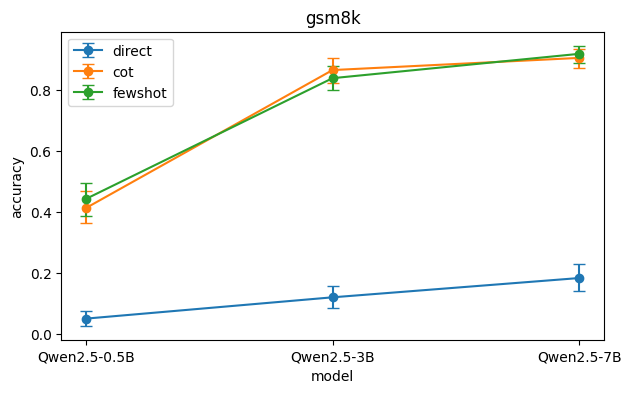

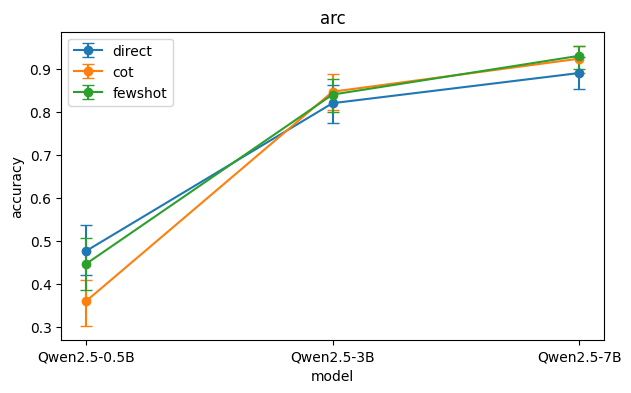

In [9]:
for dataset in ["gsm8k", "arc"]:
    a = acc[acc["dataset"] == dataset]
    plt.figure(figsize=(7, 4))
    for mode in ["direct", "cot", "fewshot"]:
        b = a[a["mode"] == mode]
        plt.errorbar(b["model"], b["acc"], yerr=[b["acc"] - b["low"], b["high"] - b["acc"]],
                     marker="o", capsize=4, label=mode)
    plt.title(dataset)
    plt.xlabel("model")
    plt.ylabel("accuracy")
    plt.legend()
    plt.show()

На GSM8K линия direct лежит у самого низа для всех моделей, а cot и fewshot почти совпадают и растут от 0.5B к 3B, дальше рост замедляется. На ARC три линии идут близко, кроме точки 0.5B, где cot ниже остальных.

In [10]:
tokens = df.groupby(["model", "dataset", "mode"])["n_tokens"].mean().reset_index()
tokens

,model,dataset,mode,n_tokens
0,Qwen2.5-0.5B,arc,cot,257.190000
1,Qwen2.5-0.5B,arc,direct,2.140000
2,Qwen2.5-0.5B,arc,fewshot,129.036667
3,Qwen2.5-0.5B,gsm8k,cot,315.270000
4,Qwen2.5-0.5B,gsm8k,direct,3.686667
5,Qwen2.5-0.5B,gsm8k,fewshot,253.183333
6,Qwen2.5-3B,arc,cot,263.320000
7,Qwen2.5-3B,arc,direct,2.000000
8,Qwen2.5-3B,arc,fewshot,99.513333
9,Qwen2.5-3B,gsm8k,cot,286.716667


CoT генерирует 257-315 токенов против 2-4 у прямого ответа, то есть в 80-130 раз больше. Few-shot даёт более короткие ответы, чем zero-shot CoT (7B на GSM8K: 191 против 275), при близкой точности.

Сравниваем режимы fewshot и cot по одним и тем же вопросам: берём разность «верно в fewshot минус верно в cot» с bootstrap-интервалом, а для токенов считаем долю экономии: 1 − (токены fewshot / токены cot).

In [15]:
rows = []
for (model, dataset), g in wide.groupby(["model", "dataset"]):
    d = (g["fewshot"] - g["cot"]).values
    boots = [rng.choice(d, size=len(d), replace=True).mean() for i in range(1000)]
    rows.append(dict(model=model, dataset=dataset, comparison="fewshot - cot",
                     diff=d.mean(), low=np.percentile(boots, 2.5), high=np.percentile(boots, 97.5)))
fs_vs_cot = pd.DataFrame(rows)
fs_vs_cot

,model,dataset,comparison,diff,low,high
0,Qwen2.5-0.5B,arc,fewshot - cot,0.086667,0.019917,0.156667
1,Qwen2.5-0.5B,gsm8k,fewshot - cot,0.030000,-0.030000,0.083333
2,Qwen2.5-3B,arc,fewshot - cot,-0.006667,-0.053333,0.036667
3,Qwen2.5-3B,gsm8k,fewshot - cot,-0.026667,-0.063333,0.006667
4,Qwen2.5-7B,arc,fewshot - cot,0.006667,-0.026667,0.040000
5,Qwen2.5-7B,gsm8k,fewshot - cot,0.013333,-0.010000,0.036667


In [16]:
t = df.pivot_table(index=["dataset", "model"], columns="mode", values="n_tokens")
(1 - t["fewshot"] / t["cot"]).round(2)

dataset  model       
arc      Qwen2.5-0.5B    0.50
         Qwen2.5-3B      0.62
         Qwen2.5-7B      0.67
gsm8k    Qwen2.5-0.5B    0.20
         Qwen2.5-3B      0.26
         Qwen2.5-7B      0.31
dtype: float64

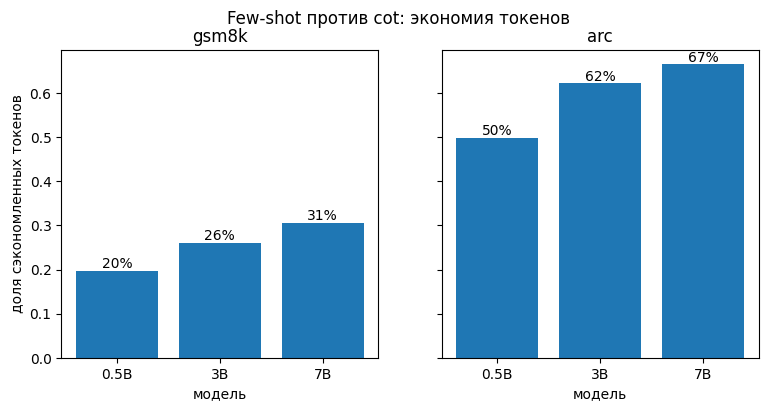

In [22]:
models = ["Qwen2.5-0.5B", "Qwen2.5-3B", "Qwen2.5-7B"]

t = df.pivot_table(index=["dataset", "model"], columns="mode", values="n_tokens")
saving = 1 - t["fewshot"] / t["cot"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, dataset in zip(axes, ["gsm8k", "arc"]):
    s = saving[dataset].loc[models]
    bars = ax.bar([m.replace("Qwen2.5-", "") for m in models], s.values)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in s.values])
    ax.set_title(dataset)
    ax.set_xlabel("модель")
axes[0].set_ylabel("доля сэкономленных токенов")
fig.suptitle("Few-shot против cot: экономия токенов")
plt.show()

Гипотеза 3: Few-shot даёт такую же точность, как cot без примеров, но с меньшим числом сгенерированных токенов. Подтверждена.

В пяти из шести случаев интервал включает ноль, то есть различий в точности не видно. У 0.5B на ARC few-shot даже лучше (+0.09). Ни в одном случае few-shot не оказался заметно хуже. Few-shot пишет короче во всех случаях, экономия растёт с размером модели и больше на ARC.

**Считаются только сгенерированные токены, подсказка с примерами у few-shot длиннее, поэтому общая стоимость запроса может отличаться. 

## Часть 2. От чего зависит выигрыш от CoT на GSM8K

In [23]:
g = df[df["dataset"] == "gsm8k"]
print(g[["gold_n_steps", "n_steps"]].isna().sum())
print(g["gold_n_steps"].describe())

gold_n_steps    0
n_steps         0
dtype: int64
count    2700.000000
mean        3.680000
std         1.507241
min         2.000000
25%         3.000000
50%         3.000000
75%         4.000000
max         9.000000
Name: gold_n_steps, dtype: float64
